# Stimulus sampling → `stimulus_sampling.pdf`

Two panels: the stimulus ring with two example objects at $\theta_0$ and $\theta_1$, and
where the two objects actually sat across every 2-object trial, one dot per trial.

The over-represented east-west antipodal pair (one object at 0°, the other at 180°, repeated
thousands of times) is dropped, as it is in every analysis here — see `../trial_filters.py`.

In [4]:
import numpy as np
from matplotlib import pyplot as plt

import common

common.set_style()

FIGSIZE = (2.4, 4.0)
OUTPUT = 'stimulus_sampling.pdf'

# The ring panel's scale bar: its length in degrees of visual angle, and where its centre sits
# in the panel's display units. The ring has radius 0.35 there and the panel spans +/- 0.5, so
# the bar sits below the ring and right of centre, where the ring's arc has risen far enough
# to leave room for the label above the bar.
REMOVE_SCALE_BAR = True   # True drops the scale bar and its label from the ring panel
RING_RADIUS_DEG = 8.4   # the stimulus ring's radius, in degrees of visual angle
SCALE_BAR_DEG = 5.0
SCALE_BAR_X = 0.37
SCALE_BAR_Y = -0.38
SCALE_BAR_LABEL_X = 0.39    # the label's centre, in the same units
SCALE_BAR_LABEL_Y = -0.5

In [5]:
ring = common.load_ring()
radius = common.ring_radius(ring)
two = ring[ring['num_objects'] == 2]

theta_0 = two['object_0_theta'].to_numpy(float) % (2 * np.pi)
theta_1 = two['object_1_theta'].to_numpy(float) % (2 * np.pi)
finite = np.isfinite(theta_0) & np.isfinite(theta_1)
theta_0, theta_1 = theta_0[finite], theta_1[finite]

# The repeated east-west antipodal pair, dropped as it is everywhere else.
east_west = common.east_west_mask(theta_0, theta_1)
theta_0, theta_1 = theta_0[~east_west], theta_1[~east_west]
print(f'{east_west.sum()} east-west trials dropped, {len(theta_0)} plotted; '
      f'ring radius {radius:.3f}')

2279 east-west trials dropped, 34052 plotted; ring radius 0.350


saved stimulus_sampling.pdf


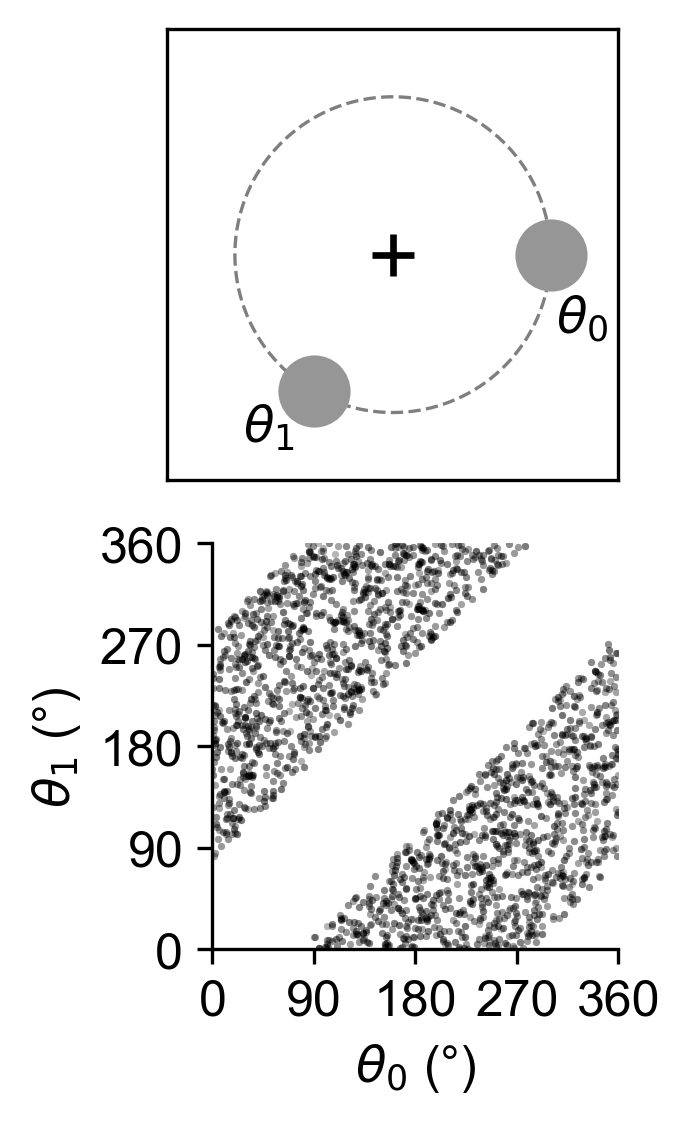

In [6]:
fig, (ax_ring, ax) = plt.subplots(2, 1, figsize=FIGSIZE)

common.draw_ring(ax_ring, radius)
for angle_deg, (dx, dy), label in [(0.0, (0.07, -0.14), r'$\theta_0$'),
                                   (240.0, (-0.1, -0.08), r'$\theta_1$')]:
    a = np.radians(angle_deg)
    x, y = radius * np.cos(a), radius * np.sin(a)
    ax_ring.scatter(x, y, s=300, color='0.59', linewidths=0, zorder=5)
    ax_ring.text(x + dx, y + dy, label, ha='center', va='center', fontsize=12, zorder=7)

# The scale bar, centred on (SCALE_BAR_X, SCALE_BAR_Y), with its label at (SCALE_BAR_LABEL_X,
# SCALE_BAR_LABEL_Y) and sitting up from there. The ring's radius is RING_RADIUS_DEG of visual
# angle, which fixes the display units the panel is drawn in, so SCALE_BAR_DEG is that fraction
# of the ring's radius.
if not REMOVE_SCALE_BAR:
    half = 0.5 * SCALE_BAR_DEG * radius / RING_RADIUS_DEG
    ax_ring.plot([SCALE_BAR_X - half, SCALE_BAR_X + half], [SCALE_BAR_Y, SCALE_BAR_Y], color='k',
                 lw=2, solid_capstyle='butt', zorder=7)
    ax_ring.text(SCALE_BAR_LABEL_X, SCALE_BAR_LABEL_Y, f'{SCALE_BAR_DEG:g}°', ha='center',
                 va='bottom', fontsize=12, zorder=7)

common.clean_square(ax_ring, 0.5)

ax.scatter(np.degrees(theta_0), np.degrees(theta_1), s=3, alpha=0.03, linewidths=0,
           color='k')
ax.set_xlabel(r'$\theta_0$ (°)')
ax.set_ylabel(r'$\theta_1$ (°)')
ax.set_xlim(0, 360)
ax.set_ylim(0, 360)
ax.set_aspect('equal')
ax.set_xticks(range(0, 361, 90))
ax.set_yticks(range(0, 361, 90))
common.despine(ax)
fig.tight_layout()

# Shrink the scatter panel slightly about its top-right corner, so its tick labels and axis
# label do not protrude further left than the ring panel above it.
box = ax.get_position()
ax.set_position([box.x1 - 0.9 * box.width, box.y1 - 0.9 * box.height,
                 0.9 * box.width, 0.9 * box.height])

common.save(fig, OUTPUT)
plt.show()